In [1]:
import matplotlib.pyplot as plt
from polytope_cooling.systems import SingleSystem, CombinedSystem
import numpy as np

alpha_goal = 0.9

energies = []


def get_step_data_gaps(gaps: list[float], temp=10) -> list[tuple[float, float]]:
    system = SingleSystem.maximally_mixed([0, 1])
    machine = SingleSystem.thermal_system_from_temperature_and_gaps(gaps, temp)
    combined = CombinedSystem.from_systems(system, machine)
    a_min = combined.min_alpha()
    steps = list(a_min.construct_path(alpha_goal))
    return [(step.alpha, step.trace_out_system().energy - combined.trace_out_system().energy) for step in steps]

def get_step_data_levels(levels: list[float], temp=10) -> list[tuple[float, float]]:
    system = SingleSystem.maximally_mixed([0, 1])
    machine = SingleSystem.thermal_system_from_temperature_and_levels(levels, temp)
    combined = CombinedSystem.from_systems(system, machine)
    a_min = combined.min_alpha()
    steps = list(a_min.construct_path(alpha_goal))
    return [(step.alpha, step.trace_out_system().energy - combined.trace_out_system().energy) for step in steps]

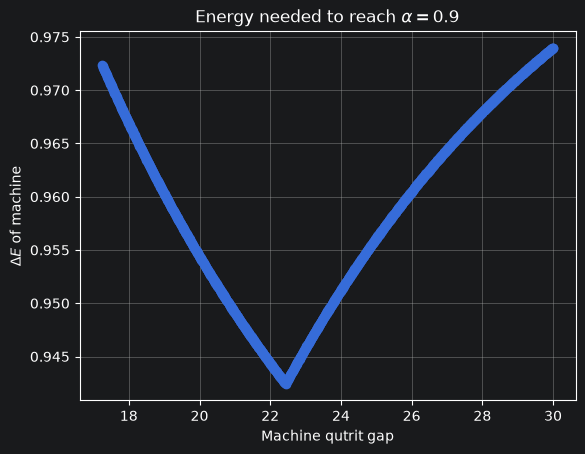

(np.float64(22.43377350940376), np.float64(0.9424472954919152))


In [2]:
for gap in np.linspace(1, 30, 2500):
    step_data = get_step_data_levels([0, gap, 2 * gap])
    if step_data[-1][0] < alpha_goal:
        continue
    energies.append((gap, np.interp(alpha_goal, step_data[-2], step_data[-1])))

gap_values, e_values = zip(*energies)
plt.plot(gap_values, e_values, marker='o')
plt.xlabel(r"Machine qutrit gap")
plt.ylabel(r"$\Delta E$ of machine")
plt.title(rf'Energy needed to reach $\alpha={alpha_goal}$')
ax = plt.gca()
#ax.set_ylim((0, ax.get_ylim()[1]))
plt.grid(True)
plt.show()

print(energies[np.argmin(e_values)])

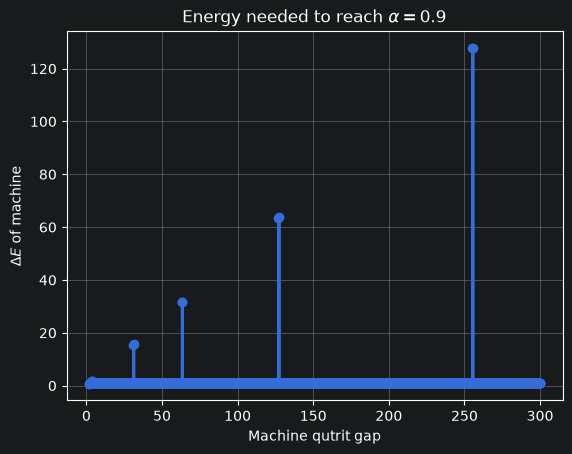

(np.float64(1.800720288115246), np.float64(0.7344407704513176))


In [3]:
for gap in np.linspace(0, 300, 2500):
    step_data = get_step_data_levels([0, gap, 2 * gap], temp=1)
    if step_data[-1][0] < alpha_goal:
        continue
    energies.append((gap, np.interp(alpha_goal, step_data[-2], step_data[-1])))

gap_values, e_values = zip(*energies)
plt.plot(gap_values, e_values, marker='o')
plt.xlabel(r"Machine qutrit gap")
plt.ylabel(r"$\Delta E$ of machine")
plt.title(rf'Energy needed to reach $\alpha={alpha_goal}$')
ax = plt.gca()
#ax.set_ylim((0, ax.get_ylim()[1]))
plt.grid(True)
plt.show()

print(energies[np.argmin(e_values)])

In [22]:
from matplotlib import colors
import numpy as np

energies = []
nx = 100
ny = 100
gapX = np.linspace(0, 100, nx)
gapY = np.linspace(0, 100, ny)

gap_values, gap2_values_ = np.meshgrid(gapX, gapY, indexing="ij")
gap2_values = gap2_values_
for gapi in range(nx):
    energy_line = []
    for gapj in range(ny):
        step_data = get_step_data_gaps([gap_values[gapi, gapj], gap2_values[gapi, gapj]], temp=10)
        if step_data[-1][0] < alpha_goal:
            energy_line.append(np.nan)
        else:
            energy_line.append(np.interp(alpha_goal, step_data[-2], step_data[-1]))
    energies.append(energy_line)

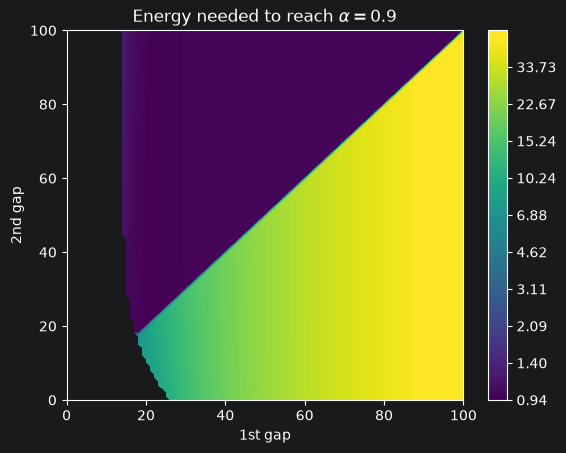

In [23]:
from matplotlib.ticker import FormatStrFormatter

energies_fixed = np.array(energies)

min = np.nanmin(energies_fixed)
max =  np.nanmax(energies_fixed)
levelsLog = np.logspace(np.log10(min), np.log10(max), 1000)
levelsLin = np.linspace(min, max, 1000)
conplot = plt.contourf(gap_values, gap2_values_, energies_fixed, levels=levelsLog, norm=colors.LogNorm(min, max-(max-min)*0.1))
cbar = plt.colorbar(conplot)
#cbar.set_ticks(np.logspace(np.log10(min), np.log10(max), 10))
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
#cbar.ax.minorticks_off()
plt.xlabel(r"1st gap")
plt.ylabel(r"2nd gap")
plt.title(rf'Energy needed to reach $\alpha={alpha_goal}$')
plt.show()

#print(energies[np.argmin(e_values)])

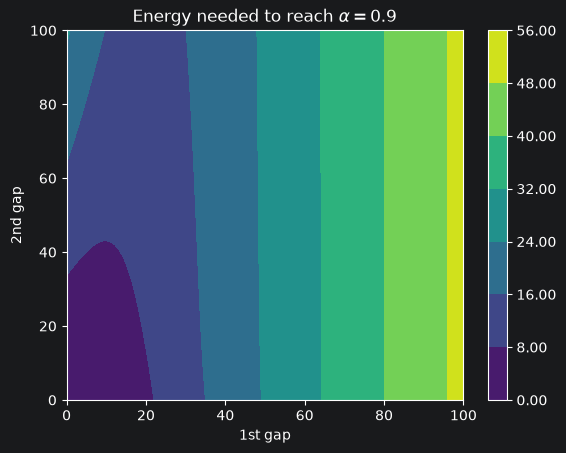

In [37]:
from matplotlib.ticker import FormatStrFormatter
import numpy as np

def z(gap, gap2, beta):
    return 1+np.exp(-gap*beta)+np.exp(-gap2*beta)

def formula(gap, gap2, beta):
    return 1/(2*z(gap, gap2, beta)) * (gap*(1+np.exp(-gap2*beta)-2*np.exp(-gap*beta)) + gap2*(np.exp(-gap*beta)-np.exp(-gap2*beta)))

energies = []
nx = 100
ny = 100
gapX = np.linspace(0, 100, nx)
gapY = np.linspace(0, 100, ny)
gap_values, gap2_values = np.meshgrid(gapX, gapY, indexing="ij")
temp = 10
for gapi in range(nx):
    energy_line = []
    for gapj in range(ny):
        energy_line.append(formula(gap_values[gapi, gapj], gap_values[gapi, gapj]+gap2_values[gapi, gapj], 1/temp))
    energies.append(energy_line)
energies_fixed = np.array(energies)

min = np.nanmin(energies_fixed+1e-50)
max =  np.nanmax(energies_fixed)
levelsLog = np.logspace(np.log10(min), np.log10(max), 10000)
#levelsLin = np.linspace(min, max, 1000)
conplot = plt.contourf(gap_values, gap2_values, energies_fixed)#, levels=levelsLog)#, norm=colors.LogNorm(min, max-(max-min)*0.999))
cbar = plt.colorbar(conplot)
#cbar.set_ticks(np.logspace(np.log10(min), np.log10(max), 10))
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
#cbar.ax.minorticks_off()
plt.xlabel(r"1st gap")
plt.ylabel(r"2nd gap")
plt.title(rf'Energy needed to reach $\alpha={alpha_goal}$')
plt.show()

#print(energies[np.argmin(e_values)])

In [ ]:
from scipy.optimize import minimize, shgo, differential_evolution
import numpy as np

def energy(gaps: list[float]) -> float:
    step_data = get_step_data_levels(gaps)
    if step_data[-1][0] < alpha_goal:
        return np.nan
    return np.interp(alpha_goal, step_data[-2], step_data[-1])

# Safe wrapper handling NaN and the x1 < x2 constraint
def objective_wrapper(params):
    x1, x2 = params
    if x1 <= 0 or x2 <= 0:
        return 1e10  # Large finite penalty instead of inf (better for DE)

    result = energy([x1, x2])
    if np.isnan(result):
        return 1e10

    return result
# make sure the initial guess does reach target alpha
initial_gaps = np.array([125, 500])

constraints = [
    #{'type': 'ineq', 'fun': lambda x: x[1] - x[0]},
    {'type': 'ineq', 'fun': lambda x: x[0]},
    {'type': 'ineq', 'fun': lambda x: x[1]}
]

#result = shgo(objective_wrapper, bounds=[(0,np.inf), (0,np.inf)], constraints=constraints)

bounds = [(1e-5, 2000.0), (1e-5, 2000.0)]
result = differential_evolution(objective_wrapper, bounds, #strategy='best1bin',
    popsize=200, mutation=(0.5, 1), recombination=0.7, seed=42, #workers=-1
)

# Display results
print(f"Optimal solution: {result.x}")
print(f"Minimum value: {result.fun}")
print(f"Success: {result.success}")